# T12: bit-identical speed-up, figures

Every figure is rebuilt from `data/` (written by `collect_data.py` from the run directories).

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
DATA = Path("data"); FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BEFORE, AFTER = "#8c8c8c", "#1f77b4"
st = pd.read_csv(DATA / "stage_times.csv")
ps = pd.read_csv(DATA / "per_star_runtime.csv")
wk = pd.read_csv(DATA / "worker_scaling.csv")
ids = pd.read_csv(DATA / "identity_checks.csv")
wall = pd.read_csv(DATA / "run_wall_seconds.csv")

## 1. Per-stage time, before vs after

Serial, idle machine, 15 dev_medium stars (3 per period bin) x 3 interleaved repeats, both coverage modes, `--features` on. Bars are the mean seconds per star of each stage (mean over stars of the per-star median over repeats).

mode                       assigned        fullyear       
code                          after before    after before
load                          0.045  0.049    0.048  0.049
descriptors                   0.007  0.007    0.013  0.013
ACF (both views)              0.008  0.017    0.017  0.034
guess: wavelet                0.190  0.408    0.339  0.680
guess: acf_fft_highpass       0.042  0.133    0.088  0.280
guess: Lomb-Scargle (both)    0.021  0.045    0.039  0.083
guess: acf_fft (both)         0.015  0.017    0.033  0.039
guess: pairwise_histogram     0.002  0.002    0.003  0.003
comb fit                      0.746  0.973    0.976  1.268
gate records                  0.000  0.000    0.000  0.000
ml_features                   0.102  0.215    0.143  0.335
total                         1.184  1.871    1.713  2.782

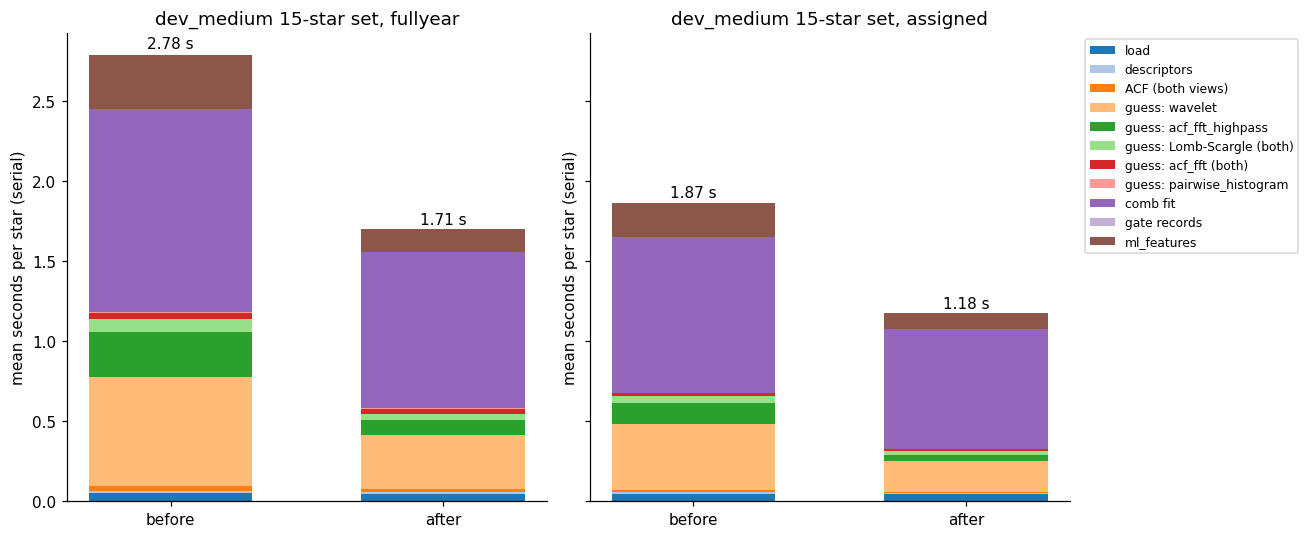

In [2]:
GROUPS = {"load": ["load"], "descriptors": ["descriptors"], "ACF (both views)": ["acf_long", "acf_short"],
          "guess: wavelet": ["guess_wavelet"], "guess: acf_fft_highpass": ["guess_acf_fft_highpass"],
          "guess: Lomb-Scargle (both)": ["guess_lombscargle", "guess_lombscargle_short"],
          "guess: acf_fft (both)": ["guess_acf_fft", "guess_acf_fft_short"],
          "guess: pairwise_histogram": ["guess_pairwise_histogram"],
          "comb fit": ["fit"], "gate records": ["gate_records"], "ml_features": ["features"]}
med = st.groupby(["code", "mode", "star_id"]).median(numeric_only=True).reset_index()
for g, cols in GROUPS.items():
    med[g] = med[cols].sum(axis=1)
per = med.groupby(["mode", "code"])[list(GROUPS) + ["total"]].mean()
stage_table = per.T.round(3)
stage_table.to_csv(DATA / "stage_table.csv")
display(stage_table)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
cmap = plt.get_cmap("tab20")
for ax, mode in zip(axes, ["fullyear", "assigned"]):
    bottom = np.zeros(2)
    for k, g in enumerate(GROUPS):
        vals = np.array([per.loc[(mode, c), g] for c in ("before", "after")])
        ax.bar(["before", "after"], vals, bottom=bottom, color=cmap(k), label=g, width=0.6)
        bottom += vals
    for x, c in enumerate(("before", "after")):
        ax.text(x, bottom[x] * 1.01, f"{per.loc[(mode, c), 'total']:.2f} s", ha="center", va="bottom")
    ax.set_title(f"dev_medium 15-star set, {mode}"); ax.set_ylabel("mean seconds per star (serial)")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "fig_stage_breakdown.png", bbox_inches="tight")

## 2. Per-stage speed-up (which change bought what)

Ratio before/after of each stage's mean time. Change 1 shows up in the four ACF-independent guess methods, changes 2-3 in the comb fit, change 4 in the ACF and the high-pass guess, changes 5-6 in ml_features.

mode,assigned,fullyear
load,1.08,1.02
descriptors,1.07,1.01
ACF (both views),2.04,2.02
guess: wavelet,2.15,2.01
guess: acf_fft_highpass,3.17,3.18
guess: Lomb-Scargle (both),2.14,2.13
guess: acf_fft (both),1.15,1.19
guess: pairwise_histogram,1.07,1.04
comb fit,1.31,1.30
gate records,1.09,1.00


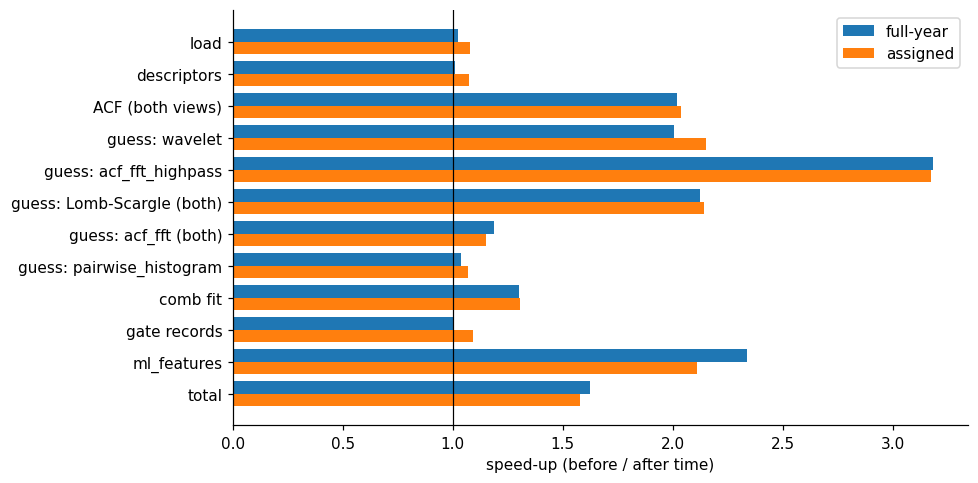

In [3]:
sp = (per.xs("before", level="code") / per.xs("after", level="code")).T
display(sp.round(2))
sp.to_csv(DATA / "stage_speedup.csv")
fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(sp.index))
ax.barh(y - 0.2, sp["fullyear"], height=0.4, label="full-year", color=AFTER)
ax.barh(y + 0.2, sp["assigned"], height=0.4, label="assigned", color="#ff7f0e")
ax.axvline(1, color="k", lw=0.8)
ax.set_yticks(y, sp.index); ax.invert_yaxis(); ax.set_xlabel("speed-up (before / after time)")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "fig_stage_speedup.png", bbox_inches="tight")

## 3. Per-star runtime distribution (dev_medium, 4-worker scorecards)

`seconds` per star from the back-to-back before/after timing runs (03:04-03:35, idle machine). These include 4-worker contention; the scorecard path has no ml_features.

,mode,n,median_before,median_after,p90_before,p90_after,mean_before,mean_after,median_paired_speedup,median_speedup,p90_speedup,mean_speedup
0,fullyear,1000,2.665,1.729,3.205,2.121,2.704,1.728,1.539,1.541,1.511,1.565
1,assigned,1000,1.562,1.075,2.448,1.620,1.594,1.084,1.469,1.454,1.511,1.471


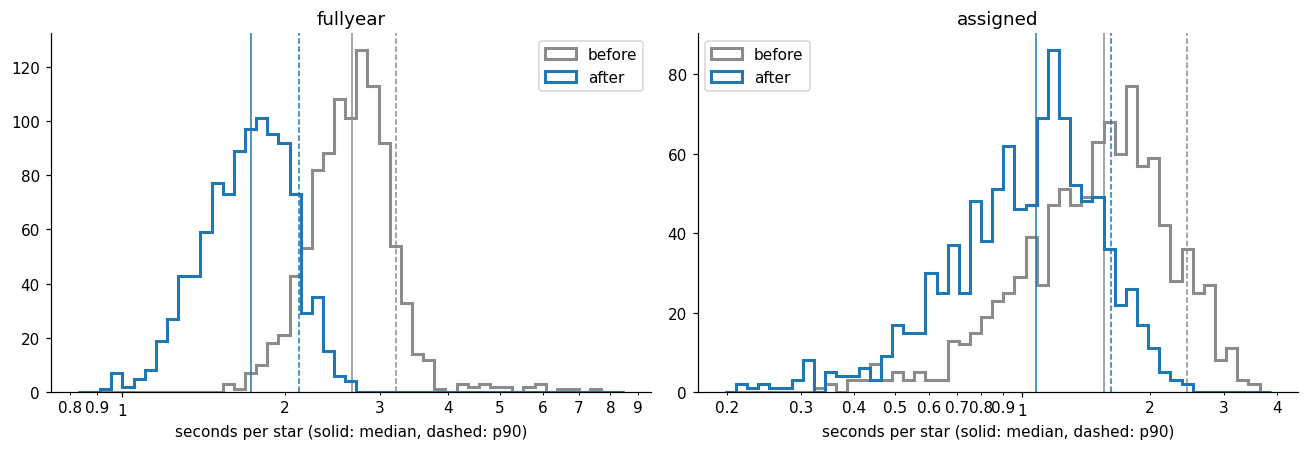

In [4]:
summ = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, mode in zip(axes, ["fullyear", "assigned"]):
    d = ps[ps["mode"] == mode]
    bins = np.logspace(np.log10(min(d.seconds_before.min(), d.seconds_after.min()) * 0.9),
                       np.log10(max(d.seconds_before.max(), d.seconds_after.max()) * 1.1), 50)
    for col, c, lab in (("seconds_before", BEFORE, "before"), ("seconds_after", AFTER, "after")):
        ax.hist(d[col], bins=bins, histtype="step", lw=2, color=c, label=lab)
        for q, ls in ((0.5, "-"), (0.9, "--")):
            ax.axvline(d[col].quantile(q), color=c, ls=ls, lw=1)
    ax.set_xscale("log"); ax.set_xlabel("seconds per star (solid: median, dashed: p90)"); ax.set_title(mode)
    ax.xaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.FormatStrFormatter("%g"))
    ax.legend()
    summ.append(dict(mode=mode, n=len(d), median_before=d.seconds_before.median(), median_after=d.seconds_after.median(),
                     p90_before=d.seconds_before.quantile(0.9), p90_after=d.seconds_after.quantile(0.9),
                     mean_before=d.seconds_before.mean(), mean_after=d.seconds_after.mean(),
                     median_paired_speedup=(d.seconds_before / d.seconds_after).median()))
fig.tight_layout(); fig.savefig(FIG / "fig_runtime_distribution.png", bbox_inches="tight")
summ = pd.DataFrame(summ)
summ["median_speedup"] = summ.median_before / summ.median_after
summ["p90_speedup"] = summ.p90_before / summ.p90_after
summ["mean_speedup"] = summ.mean_before / summ.mean_after
summ.to_csv(DATA / "runtime_summary.csv", index=False)
display(summ.round(3))

## 4. Speed-up by period bin and coverage class

Paired per-star ratio before/after (dev_medium scorecards), median and IQR per group.

mode                             assigned  fullyear
group          value                               
coverage_class consecutive-2         1.36       NaN
               consecutive-3-5       1.38       NaN
               consecutive-6-12      1.45      1.55
               full                  1.54      1.55
               gapped-2              1.53       NaN
               gapped-3-5            1.56       NaN
               gapped-6-12           1.55      1.54
               single                1.37       NaN
period_bin     1-3d                  1.49      1.51
               10-30d                1.46      1.52
               3-10d                 1.48      1.54
               <1d                   1.47      1.58
               >30d                  1.45      1.55

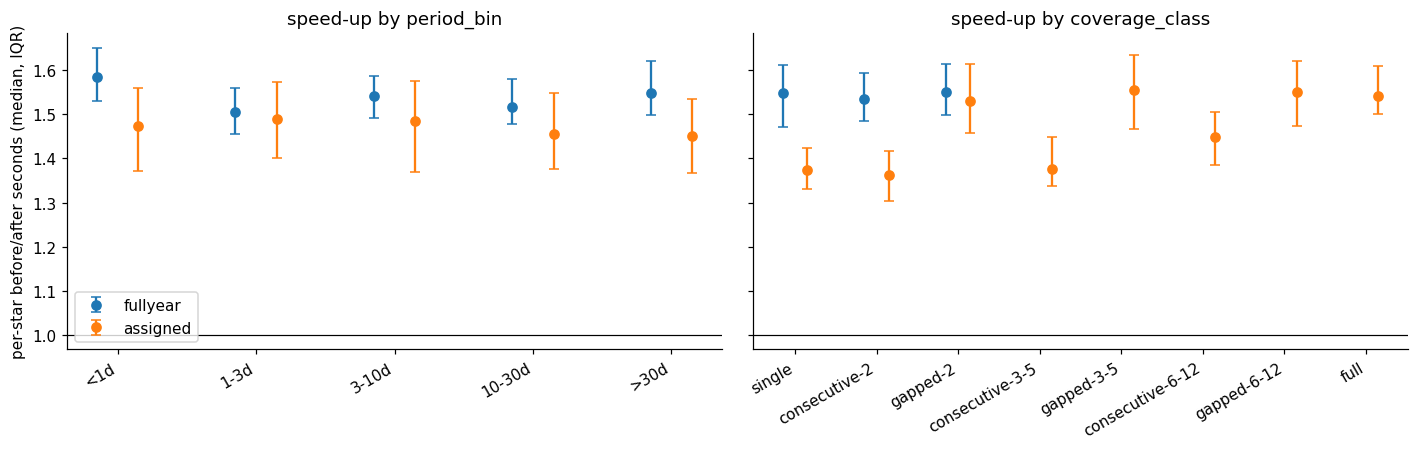

In [5]:
ps["speedup"] = ps.seconds_before / ps.seconds_after
BIN_ORDER = ["<1d", "1-3d", "3-10d", "10-30d", ">30d"]
COV_ORDER = ["single", "consecutive-2", "gapped-2", "consecutive-3-5", "gapped-3-5", "consecutive-6-12",
             "gapped-6-12", "full"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
rows_out = []
for ax, col, order in ((axes[0], "period_bin", BIN_ORDER), (axes[1], "coverage_class", COV_ORDER)):
    for k, (mode, c) in enumerate((("fullyear", AFTER), ("assigned", "#ff7f0e"))):
        d = ps[ps["mode"] == mode]
        g = d.groupby(col)["speedup"]
        keys = [o for o in order if o in g.groups]
        q = g.quantile([0.25, 0.5, 0.75]).unstack().reindex(keys)
        x = np.arange(len(keys)) + (k - 0.5) * 0.3
        ax.errorbar(x, q[0.5], yerr=[q[0.5] - q[0.25], q[0.75] - q[0.5]], fmt="o", color=c, label=mode, capsize=3)
        for key in keys:
            rows_out.append(dict(group=col, value=key, mode=mode, median_speedup=q.loc[key, 0.5],
                                 n=int(g.size()[key])))
    ax.set_xticks(np.arange(len(keys)), keys, rotation=30, ha="right"); ax.axhline(1, color="k", lw=0.8)
    ax.set_title(f"speed-up by {col}")
axes[0].set_ylabel("per-star before/after seconds (median, IQR)"); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "fig_speedup_by_bin_coverage.png", bbox_inches="tight")
display(pd.DataFrame(rows_out).pivot_table(index=["group", "value"], columns="mode", values="median_speedup").round(2))

## 5. Worker-count scaling (dev_small full-year, 50 stars, optimized code)

,n_workers,wall,wall_min,wall_max,n,stars_per_min
0,2,41.04,38.42,43.66,50,73.10
1,4,26.52,24.02,29.03,50,113.10
2,6,24.04,23.41,24.68,50,124.78
3,8,24.21,23.95,24.48,50,123.90


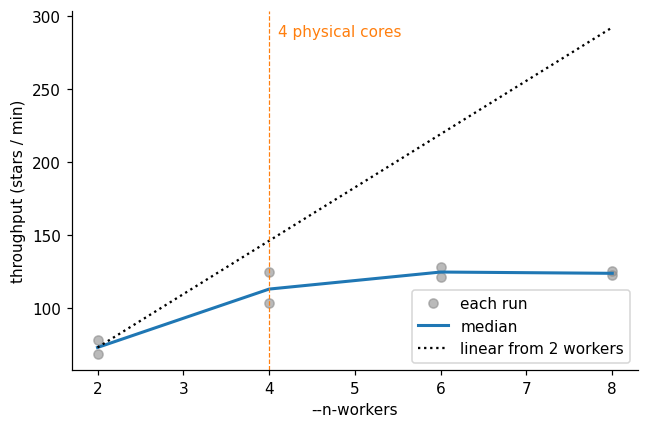

In [6]:
w = wk.groupby("n_workers").agg(wall=("wall_seconds", "median"), wall_min=("wall_seconds", "min"),
                                 wall_max=("wall_seconds", "max"), n=("n_stars", "first")).reset_index()
w["stars_per_min"] = 60 * w.n / w.wall
display(w.round(2))
w.to_csv(DATA / "worker_table.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(wk.n_workers, 60 * wk.n_stars / wk.wall_seconds, "o", color=BEFORE, alpha=0.6, label="each run")
ax.plot(w.n_workers, w.stars_per_min, "-", color=AFTER, lw=2, label="median")
ideal = w.stars_per_min.iloc[0] / w.n_workers.iloc[0] * w.n_workers
ax.plot(w.n_workers, ideal, ":", color="k", label="linear from 2 workers")
ax.axvline(4, color="#ff7f0e", lw=0.8, ls="--"); ax.text(4.1, 0.97 * ax.get_ylim()[1], "4 physical cores", color="#ff7f0e", va="top")
ax.set_xlabel("--n-workers"); ax.set_ylabel("throughput (stars / min)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fig_worker_scaling.png", bbox_inches="tight")

## 6. Bit-identical evidence

`tools/compare_runs_exact.py`: every value of every star's `rows.jsonl` record (incl. per-method candidates and per-candidate gate records) and every `metrics.json` key, or every cell of every feature-table shard; only `seconds`/`fit_seconds`, the metrics `config` and `runtime` blocks are skipped.

,check,n_stars,values_compared,n_differ,diffs
0,"dev_small full-year, after change 1",50,49277,0,NaN
1,"dev_small assigned, after change 1",50,43853,0,NaN
2,"dev_small full-year, after changes 1-3",50,49277,0,NaN
3,"dev_small assigned, after changes 1-3",50,43853,0,NaN
4,"dev_small full-year, final",50,49277,2,rows[smarts-tess-v1.0-007003].methods.wavelet....
5,"dev_small assigned, final",50,43853,0,NaN
6,"synth200, final",200,184684,5,rows[synth-s0-00017].methods.wavelet.n_candida...
7,"dev_medium full-year, final",1000,1009448,19,rows[smarts-tess-v1.0-004118].methods.wavelet....
8,"dev_medium assigned, final",1000,866262,27,rows[smarts-tess-v1.0-000141].methods.wavelet....
9,"dev_medium full-year, final (timing pair)",1000,1009448,21,rows[smarts-tess-v1.0-004118].methods.wavelet....


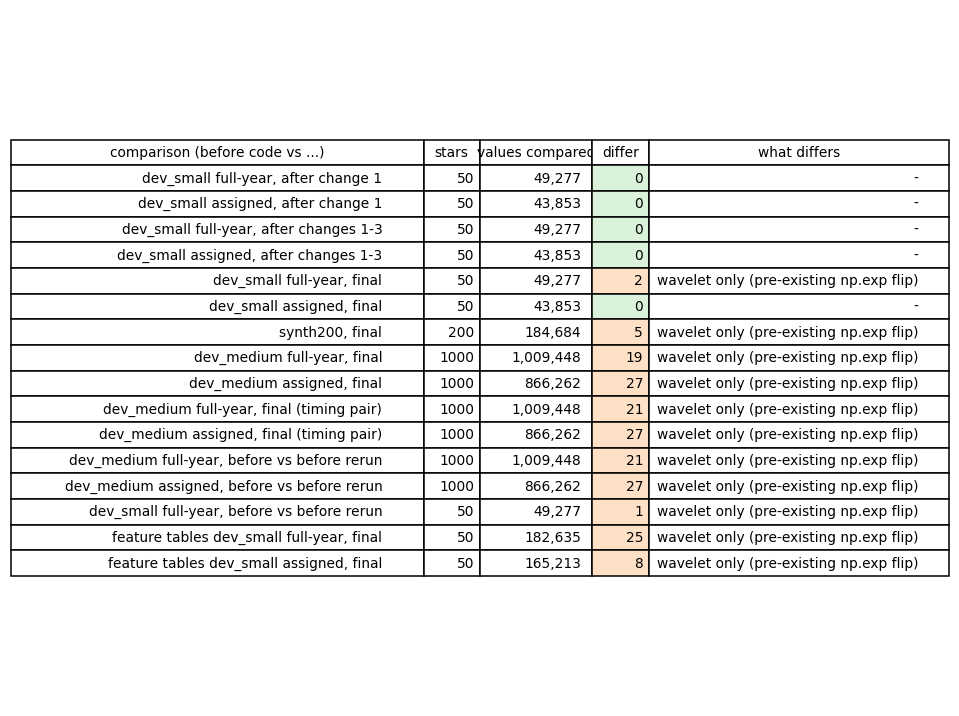

In [7]:
display(ids[["check", "n_stars", "values_compared", "n_differ", "diffs"]])
fig, ax = plt.subplots(figsize=(11, 0.45 * len(ids) + 1))
ax.axis("off")
def _what(d):
    """Short description of which fields differ."""
    if not isinstance(d, str) or not d:
        return "-"
    return "wavelet only (pre-existing np.exp flip)" if all("wavelet" in x for x in d.split("; ")) else "OTHER"
cell = [[r.check, f"{r.n_stars}", f"{r.values_compared:,}", f"{r.n_differ}", _what(r.diffs)] for r in ids.itertuples()]
tab = ax.table(cellText=cell, colLabels=["comparison (before code vs ...)", "stars", "values compared", "differ",
                                         "what differs"],
               loc="center", colWidths=[0.44, 0.06, 0.12, 0.06, 0.32])
tab.auto_set_font_size(False); tab.set_fontsize(9); tab.scale(1, 1.4)
for i, r in enumerate(ids.itertuples(), start=1):
    tab[i, 3].set_facecolor("#d9f2d9" if r.n_differ == 0 else "#fde0c5")
fig.savefig(FIG / "fig_identity_checks.png", bbox_inches="tight")

## 7. Projections: 1M stars and the ranker-table rebuild

Serial per-star seconds from section 1 for three paths: *production* (`load` -> ACF -> the 3 default methods (two views) -> comb fit), *scorecard* (all 7 Stage 1 methods + fit + bookkeeping) and *feature build* (scorecard + ml_features, = `tools/build_feature_tables.py`). 1M-star CPU-hours = serial s/star x 1e6 / 3600. Wall-clock for the rebuild uses the measured 4-worker throughput of the dev_medium after runs (wall / stars), scaled by the serial feature-build / scorecard time ratio, per coverage mode.

production  scorecard  feature_build  \
assigned after        0.813      1.082          1.184   
         before       1.062      1.656          1.871   
fullyear after        1.070      1.569          1.713   
         before       1.397      2.446          2.782   

                 production_cpu_hours_per_1M  scorecard_cpu_hours_per_1M  \
assigned after                         226.0                       301.0   
         before                        295.0                       460.0   
fullyear after                         297.0                       436.0   
         before                        388.0                       679.0   

                 feature_build_cpu_hours_per_1M  
assigned after                            329.0  
         before                           520.0  
fullyear after                            476.0  
         before                           773.0

,job,n_stars,mode,hours_before,hours_after,hours_before_drive,hours_after_drive
0,"dev_medium T10 tables, full-year",1000,fullyear,0.22,0.13,0.22,0.13
1,"dev_medium T10 tables, assigned",1000,assigned,0.13,0.08,0.13,0.08
2,"train_3k (train_v0.csv, assigned)",3000,assigned,0.38,0.25,1.27,1.15
3,"T27 negatives, coverage draws (assigned)",3531,assigned,0.45,0.30,1.00,0.85
4,"T27 negatives, full-year",1177,fullyear,0.25,0.16,0.33,0.24
5,total,9708,,1.42,0.92,2.95,2.45


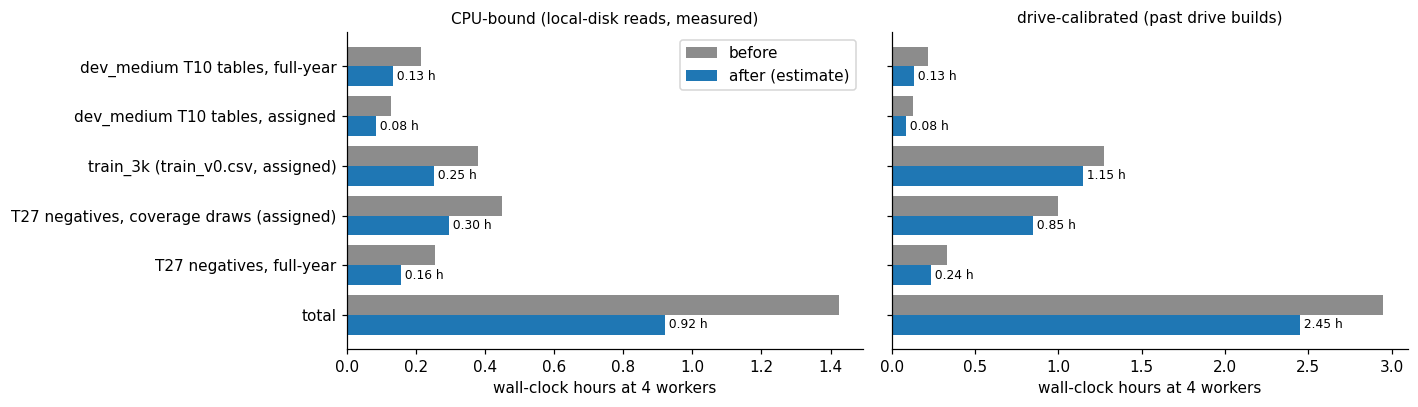

In [8]:
PROD = ["load", "acf_long", "acf_short", "guess_acf_fft", "guess_lombscargle", "guess_pairwise_histogram", "fit"]
paths = {}
for (mode, code), r in med.groupby(["mode", "code"]).mean(numeric_only=True).iterrows():
    paths[(mode, code)] = dict(production=r[PROD].sum(), scorecard=r["total"] - r["features"], feature_build=r["total"])
paths = pd.DataFrame(paths).T
proj = paths * 1e6 / 3600
proj.columns = [c + "_cpu_hours_per_1M" for c in proj.columns]
proj_tab = pd.concat([paths.round(3), proj.round(0)], axis=1)
display(proj_tab)
proj_tab.to_csv(DATA / "projection_1M.csv")
# rebuild estimate (wall-clock, 4 workers)
w4 = {}
for mode, key in (("fullyear", "dmfy"), ("assigned", "dmas")):
    r = wall[(wall.code == "runs_after_t") & (wall.run == key)].iloc[0]
    w4[mode] = r.wall_seconds / 1000  # wall seconds per star at 4 workers (scorecard path)
fb_ratio = {m: paths.loc[(m, "after"), "feature_build"] / paths.loc[(m, "after"), "scorecard"] for m in ("fullyear", "assigned")}
fb_ratio_before = {m: paths.loc[(m, "before"), "feature_build"] / paths.loc[(m, "before"), "scorecard"] for m in ("fullyear", "assigned")}
w4_before = {m: wall[(wall.code == "runs_before_t") & (wall.run == k)].iloc[0].wall_seconds / 1000
             for m, k in (("fullyear", "dmfy"), ("assigned", "dmas"))}
jobs = [("dev_medium T10 tables, full-year", 1000, "fullyear"), ("dev_medium T10 tables, assigned", 1000, "assigned"),
        ("train_3k (train_v0.csv, assigned)", 3000, "assigned"),
        ("T27 negatives, coverage draws (assigned)", 3531, "assigned"), ("T27 negatives, full-year", 1177, "fullyear")]
rb = pd.DataFrame([dict(job=j, n_stars=n, mode=m,
                        hours_before=n * w4_before[m] * fb_ratio_before[m] / 3600,
                        hours_after=n * w4[m] * fb_ratio[m] / 3600) for j, n, m in jobs])
rb.loc[len(rb)] = dict(job="total", n_stars=rb.n_stars.sum(), mode="", hours_before=rb.hours_before.sum(),
                       hours_after=rb.hours_after.sum())
# Drive-calibrated: the real drive builds were much slower than local-disk CPU time (T27 report: ~80 min for all
# 4,708 negatives at 4 workers; T10 report: ~51 min for the 2,000 train_3k stars not already in train_1k). Assume
# the extra (drive I/O, stack loading) is unchanged and subtract only the CPU time T12 saves.
measured = {"train_3k (train_v0.csv, assigned)": 51 * 60 / 2000 * 3000 / 3600,  # h for 3,000 at the 2k rate
            "T27 negatives, coverage draws (assigned)": 80 / 60 * 3531 / 4708,
            "T27 negatives, full-year": 80 / 60 * 1177 / 4708}
rb["hours_before_drive"] = [measured.get(j, hb) for j, hb in zip(rb.job, rb.hours_before)]
rb["hours_after_drive"] = rb.hours_before_drive - (rb.hours_before - rb.hours_after)
tot = rb.job == "total"
rb.loc[tot, "hours_before_drive"] = rb.loc[~tot, "hours_before_drive"].sum()
rb.loc[tot, "hours_after_drive"] = rb.loc[~tot, "hours_after_drive"].sum()
display(rb.round(2)); rb.to_csv(DATA / "rebuild_estimate.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
y = np.arange(len(rb))
for ax, (b, a, title) in zip(axes, (("hours_before", "hours_after", "CPU-bound (local-disk reads, measured)"),
                                    ("hours_before_drive", "hours_after_drive", "drive-calibrated (past drive builds)"))):
    ax.barh(y - 0.2, rb[b], height=0.4, color=BEFORE, label="before")
    ax.barh(y + 0.2, rb[a], height=0.4, color=AFTER, label="after (estimate)")
    for yy, v in zip(y, rb[a]):
        ax.text(v, yy + 0.2, f" {v:.2f} h", va="center", fontsize=8)
    ax.set_title(title, fontsize=10); ax.set_xlabel("wall-clock hours at 4 workers")
axes[0].set_yticks(y, rb.job); axes[0].invert_yaxis(); axes[0].legend()
fig.tight_layout(); fig.savefig(FIG / "fig_rebuild_estimate.png", bbox_inches="tight")